# Analyse univariée et bivariée - jeu de données PaySim

**Projet FraudLens AI - détection de fraude financière**

**Données :** PaySim, transactions de paiement mobile **simulées**, ensemble d'entraînement (steps 1 à 520, environ 6 millions de lignes).

**Variables :**
- `step` : heure écoulée depuis le début de la simulation (quantitative discrète) ;
- `amount`, `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest` : montants et soldes (quantitatives continues) ;
- `type` : type de transaction (qualitative nominale) ;
- `isFraud` : transaction frauduleuse ou non (qualitative binaire, étudiée uniquement en analyse univariée).

**Plan :**
1. Chargement et description générale
2. Analyse univariée des variables quantitatives
3. Analyse univariée des variables qualitatives
4. Analyse bivariée quantitative x quantitative : nature des relations, linéarisation, coefficient de Pearson
5. Analyse bivariée qualitative x quantitative (optionnelle)
6. Conclusions

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import PowerTransformer

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

TRAIN_PATH = ROOT / "data" / "processed" / "train.parquet"
FIG_DIR = ROOT / "reports" / "figures"
REPORTS_DIR = ROOT / "reports"
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

if not TRAIN_PATH.exists():
    raise FileNotFoundError(f"{TRAIN_PATH} introuvable. Lance d'abord : python -m fraudlens.data.prepare")

RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.options.display.float_format = "{:,.2f}".format

## 1. Chargement et description générale

In [2]:
QUANT_COLS = ["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]

df = pd.read_parquet(TRAIN_PATH, columns=QUANT_COLS + ["type", "isFraud"])

print(f"Lignes : {len(df):,} | Colonnes : {df.shape[1]}")
print("\nTypes des variables :")
print(df.dtypes.to_string())
print(f"\nValeurs manquantes : {int(df.isna().sum().sum())}")
display(df.head())

Lignes : 6,082,007 | Colonnes : 8

Types des variables :
step                 int16
amount             float64
oldbalanceOrg      float64
newbalanceOrig     float64
oldbalanceDest     float64
newbalanceDest     float64
type              category
isFraud               int8

Valeurs manquantes : 0


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,type,isFraud
0,1,"9,839.64","170,136.00","160,296.36",0.00,0.00,PAYMENT,0
1,1,"1,864.28","21,249.00","19,384.72",0.00,0.00,PAYMENT,0
2,1,181.00,181.00,0.00,0.00,0.00,TRANSFER,1
3,1,181.00,181.00,0.00,"21,182.00",0.00,CASH_OUT,1
4,1,"11,668.14","41,554.00","29,885.86",0.00,0.00,PAYMENT,0


## 2. Analyse univariée des variables quantitatives

Pour chaque variable : indicateurs de tendance centrale (moyenne, médiane), de dispersion (écart-type, quartiles, min, max), de forme (asymétrie et aplatissement), part de zéros et part de valeurs aberrantes selon la règle de **1,5 x IQR**.

In [3]:
def describe_quant(s: pd.Series) -> dict:
    s = s.astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
    skew = s.skew()
    if skew >= 0.5:
        shape = "asymétrique à droite"
    elif skew <= -0.5:
        shape = "asymétrique à gauche"
    else:
        shape = "à peu près symétrique"
    return {
        "moyenne": s.mean(),
        "médiane": s.median(),
        "écart-type": s.std(),
        "min": s.min(),
        "Q1": q1,
        "Q3": q3,
        "max": s.max(),
        "asymétrie": skew,
        "aplatissement": s.kurt(),
        "% zéros": (s == 0).mean() * 100,
        "% aberrantes (IQR)": outliers,
        "forme": shape,
    }


uni = pd.DataFrame({c: describe_quant(df[c]) for c in QUANT_COLS}).T
display(uni)

,moyenne,médiane,écart-type,min,Q1,Q3,max,asymétrie,aplatissement,% zéros,% aberrantes (IQR),forme
step,226.86,234.00,121.74,1.00,153.00,327.00,520.00,-0.25,-0.84,0.00,0.00,à peu près symétrique
amount,"180,413.05","75,131.44","609,982.68",0.00,"13,473.60","209,126.25","92,445,516.64",31.21,"1,803.06",0.00,5.31,asymétrique à droite
oldbalanceOrg,"842,037.01","13,877.00","2,920,235.74",0.00,0.00,"107,194.00","59,585,040.37",5.22,32.46,33.27,17.48,asymétrique à droite
newbalanceOrig,"863,711.96",0.00,"2,956,725.97",0.00,0.00,"144,137.36","49,585,040.37",5.15,31.62,56.85,16.56,asymétrique à droite
oldbalanceDest,"1,097,607.50","134,805.11","3,364,291.49",0.00,0.00,"946,277.78","356,015,889.35",19.90,954.39,42.39,12.32,asymétrique à droite
newbalanceDest,"1,223,550.05","216,989.78","3,650,880.30",0.00,0.00,"1,116,692.05","356,179,278.92",19.37,866.79,38.27,11.56,asymétrique à droite


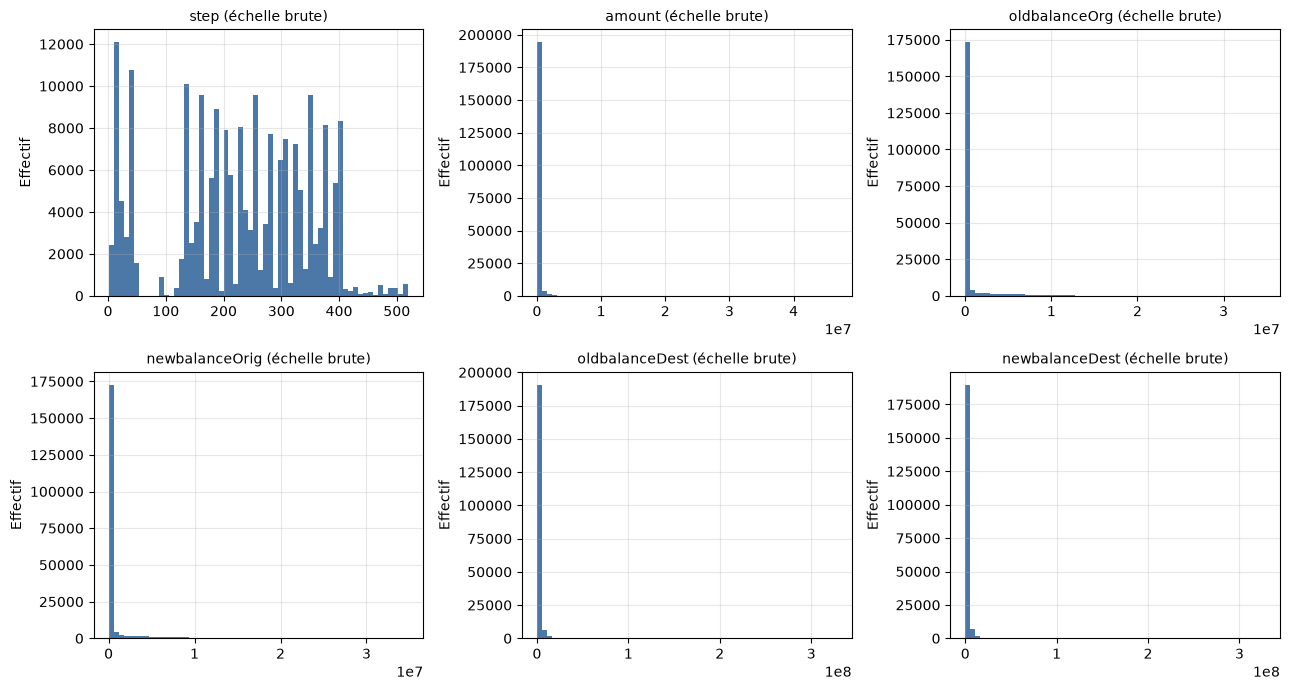

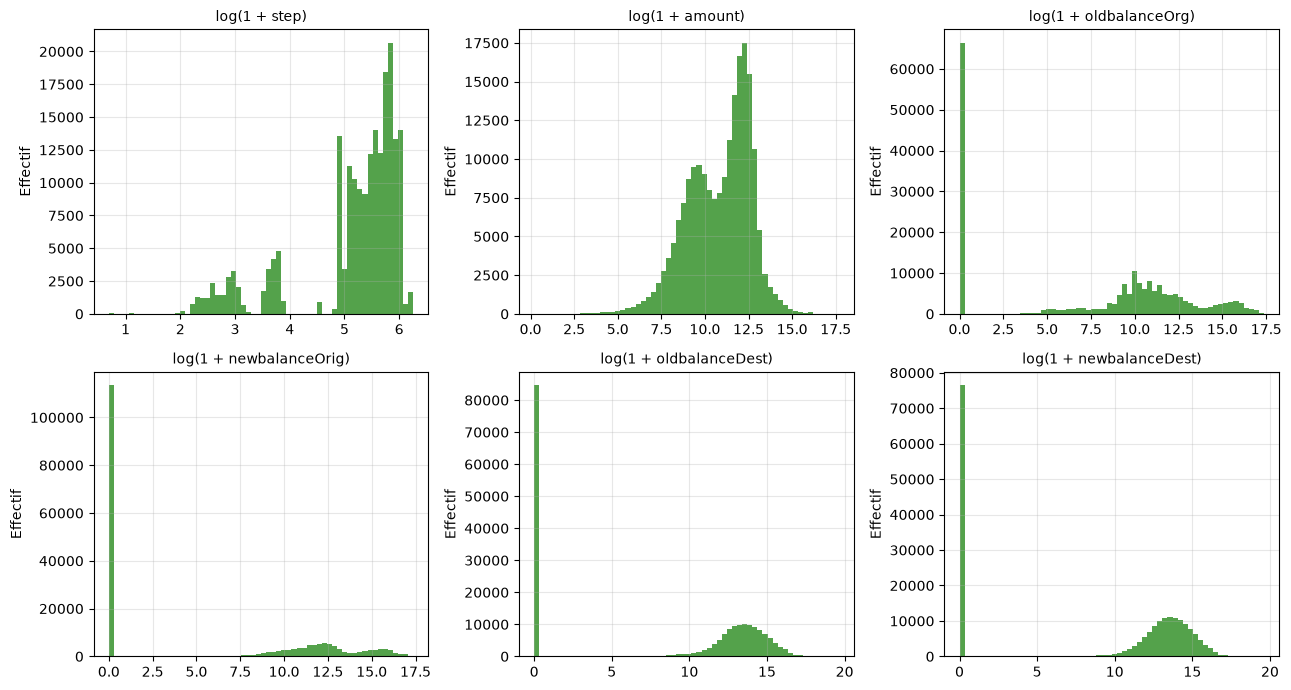

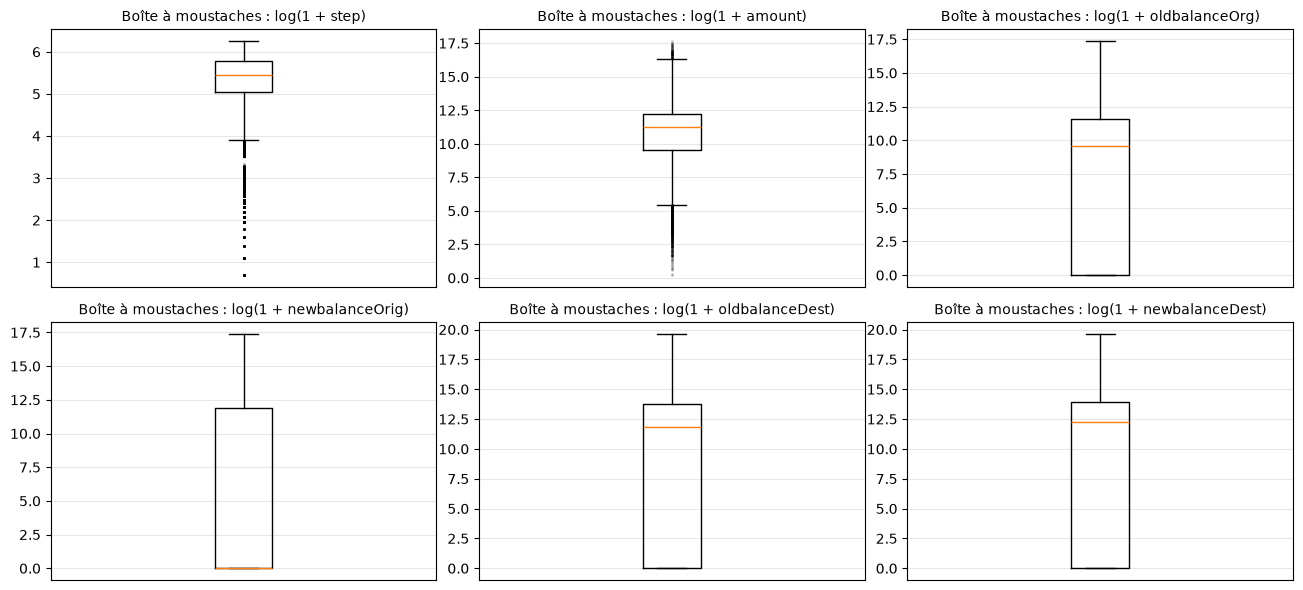

In [4]:
V = df.sample(min(200_000, len(df)), random_state=RANDOM_STATE)  # échantillon pour les graphiques

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), QUANT_COLS):
    ax.hist(V[c], bins=60, color="#4C78A8")
    ax.set_title(f"{c} (échelle brute)", fontsize=10)
    ax.set_ylabel("Effectif")
fig.tight_layout()
fig.savefig(FIG_DIR / "uni_01_histogrammes_bruts.png", dpi=130)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), QUANT_COLS):
    ax.hist(np.log1p(V[c].astype(float)), bins=60, color="#54A24B")
    ax.set_title(f"log(1 + {c})", fontsize=10)
    ax.set_ylabel("Effectif")
fig.tight_layout()
fig.savefig(FIG_DIR / "uni_02_histogrammes_log.png", dpi=130)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), QUANT_COLS):
    ax.boxplot(
        np.log1p(V[c].astype(float)),
        flierprops={"markersize": 1, "alpha": 0.2},
    )
    ax.set_title(f"Boîte à moustaches : log(1 + {c})", fontsize=10)
    ax.set_xticks([])
fig.tight_layout()
fig.savefig(FIG_DIR / "uni_03_boxplots_log.png", dpi=130)
plt.show()

**À interpréter :**
- la moyenne est-elle proche de la médiane ? Que dit l'asymétrie sur la forme de chaque distribution ?
- quelles variables contiennent beaucoup de zéros, et pourquoi (compte vide, solde non suivi) ?
- que change l'échelle logarithmique à la lecture des histogrammes ?
- que faut-il penser des valeurs aberrantes : erreurs de saisie ou montants réels très élevés ?

## 3. Analyse univariée des variables qualitatives

,effectif,fréquence (%)
type,,
CASH_OUT,2147137,35.30
PAYMENT,2053690,33.77
CASH_IN,1335450,21.96
TRANSFER,506592,8.33
DEBIT,39138,0.64


,effectif,fréquence (%)
0 = normale,6076226,99.90
1 = fraude,5781,0.10


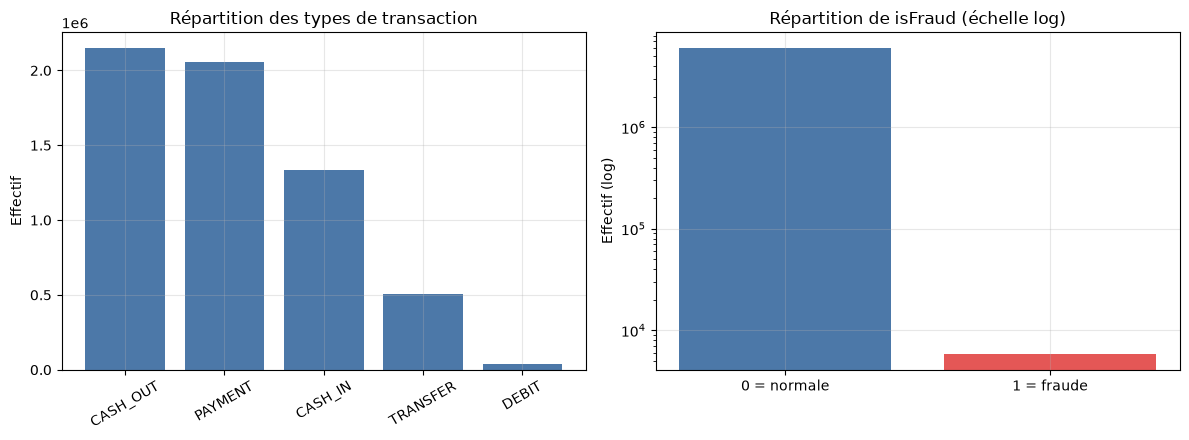

In [5]:
freq_type = df["type"].value_counts().rename("effectif").to_frame()
freq_type["fréquence (%)"] = freq_type["effectif"] / len(df) * 100
display(freq_type)

freq_fraud = df["isFraud"].value_counts().sort_index().rename("effectif").to_frame()
freq_fraud["fréquence (%)"] = freq_fraud["effectif"] / len(df) * 100
freq_fraud.index = ["0 = normale", "1 = fraude"]
display(freq_fraud)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(freq_type.index.astype(str), freq_type["effectif"], color="#4C78A8")
axes[0].set_title("Répartition des types de transaction")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Effectif")
axes[1].bar(freq_fraud.index, freq_fraud["effectif"], color=["#4C78A8", "#E45756"])
axes[1].set_yscale("log")
axes[1].set_title("Répartition de isFraud (échelle log)")
axes[1].set_ylabel("Effectif (log)")
fig.tight_layout()
fig.savefig(FIG_DIR / "uni_04_qualitatives.png", dpi=130)
plt.show()

**À interpréter :** quel est le type de transaction le plus fréquent ? Quelle part représentent les fraudes, et pourquoi ce fort déséquilibre pose-t-il problème pour l'analyse et la modélisation ?

## 4. Analyse bivariée : quantitative x quantitative

On étudie ici uniquement des **variables quantitatives**.

Pour accélérer les calculs : les coefficients sont calculés sur un échantillon de 500 000 lignes, les nuages de points et la linéarisation sur 50 000 points (2 millions de points rendraient les graphiques illisibles).

Le paramètre `TYPE_FILTER` permet de refaire toute l'analyse sur un seul type de transaction.

In [6]:
TYPE_FILTER = None  # None = tous les types ; sinon "TRANSFER", "CASH_OUT", "PAYMENT", "CASH_IN" ou "DEBIT"

base = df if TYPE_FILTER is None else df[df["type"].astype(str) == TYPE_FILTER]
S = base.sample(min(500_000, len(base)), random_state=RANDOM_STATE)
P = S.sample(min(50_000, len(S)), random_state=RANDOM_STATE)
print(f"Données analysées : {'tous les types' if TYPE_FILTER is None else TYPE_FILTER}")
print(f"Lignes de base : {len(base):,} | échantillon coefficients : {len(S):,} | échantillon graphiques : {len(P):,}")

Données analysées : tous les types
Lignes de base : 6,082,007 | échantillon coefficients : 500,000 | échantillon graphiques : 50,000


### 4.1 Matrices de corrélation

- **Pearson (r)** : force de la relation **linéaire**, de -1 à +1.
- **Spearman (rho)** : force d'une relation **monotone** (qui monte ou descend, même en courbe).

Si Spearman est nettement plus fort que Pearson, la relation est monotone mais **non linéaire**.

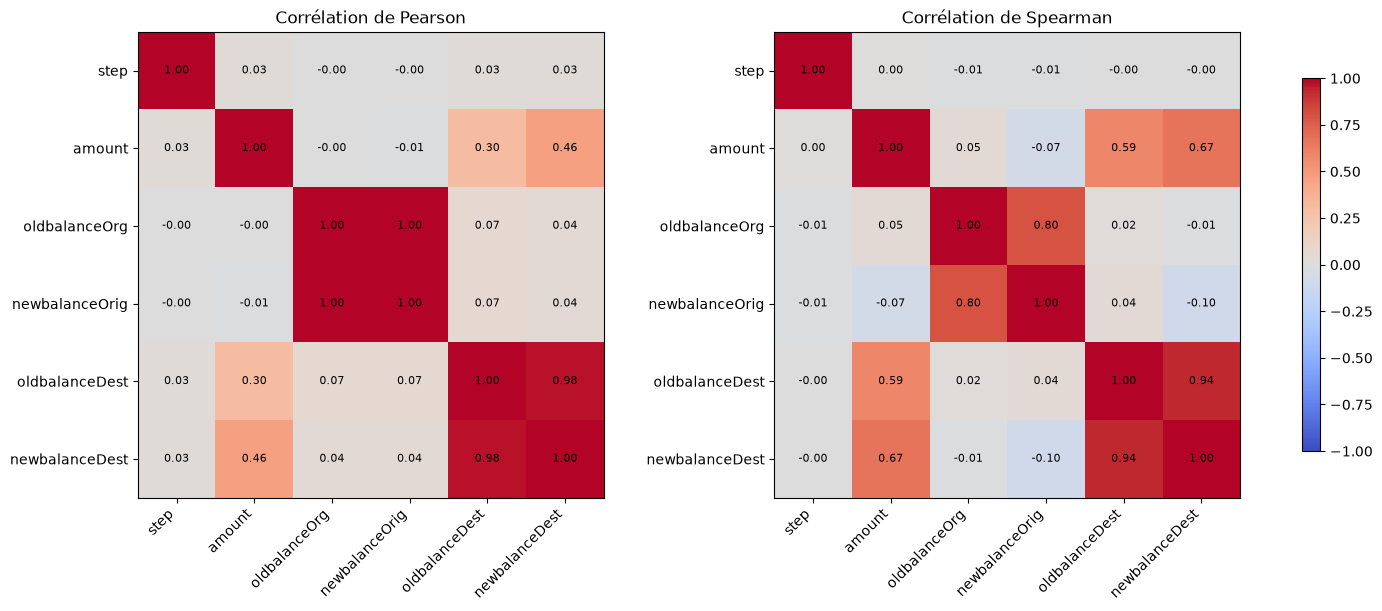

In [7]:
def heatmap(ax, corr, title):
    im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
    n = len(corr)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticklabels(corr.index)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
    ax.grid(False)
    return im


pearson_mat = S[QUANT_COLS].corr()
spearman_mat = S[QUANT_COLS].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
im = heatmap(axes[0], pearson_mat, "Corrélation de Pearson")
heatmap(axes[1], spearman_mat, "Corrélation de Spearman")
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(FIG_DIR / "bi_01_matrices_correlation.png", dpi=130)
plt.show()

### 4.2 Nature des relations

Règle de classement :
- |r| < 0,1 et |rho| < 0,1 : **sans relation apparente** ;
- |r| >= 0,5 et |r - rho| < 0,2 : **linéaire** (positive si r > 0, négative sinon) ;
- sinon : **non linéaire (ou faible)**.

Ce classement automatique est un premier avis, à **confirmer avec les nuages de points**.

In [8]:
PAIRS = [
    ("oldbalanceOrg", "newbalanceOrig"),
    ("amount", "oldbalanceOrg"),
    ("oldbalanceDest", "newbalanceDest"),
    ("amount", "newbalanceDest"),
    ("amount", "newbalanceOrig"),
    ("step", "amount"),
]


def strength(r: float) -> str:
    a = abs(r)
    if a < 0.1:
        return "négligeable"
    if a < 0.3:
        return "faible"
    if a < 0.5:
        return "modérée"
    if a < 0.7:
        return "forte"
    return "très forte"


def classify(r: float, rho: float) -> str:
    if abs(r) < 0.1 and abs(rho) < 0.1:
        return "Sans relation apparente"
    if abs(r) >= 0.5 and abs(r - rho) < 0.2:
        return "Linéaire positive" if r > 0 else "Linéaire négative"
    return "Non linéaire (ou faible)"


rows = []
r_coef = {}
for x, y in PAIRS:
    r = float(S[x].corr(S[y]))
    rho = float(S[x].corr(S[y], method="spearman"))
    r_coef[(x, y)] = r
    rows.append(
        {
            "Paire": f"{x} vs {y}",
            "Pearson r": r,
            "Spearman rho": rho,
            "R²": r**2,
            "Force (r)": strength(r),
            "Nature": classify(r, rho),
        }
    )

nature = pd.DataFrame(rows)
display(nature.round(3))

,Paire,Pearson r,Spearman rho,R²,Force (r),Nature
0,oldbalanceOrg vs newbalanceOrig,1.00,0.80,1.00,très forte,Linéaire positive
1,amount vs oldbalanceOrg,-0.01,0.04,0.00,négligeable,Sans relation apparente
2,oldbalanceDest vs newbalanceDest,0.98,0.94,0.95,très forte,Linéaire positive
3,amount vs newbalanceDest,0.46,0.67,0.21,modérée,Non linéaire (ou faible)
4,amount vs newbalanceOrig,-0.01,-0.07,0.00,négligeable,Sans relation apparente
5,step vs amount,0.03,0.00,0.00,négligeable,Sans relation apparente


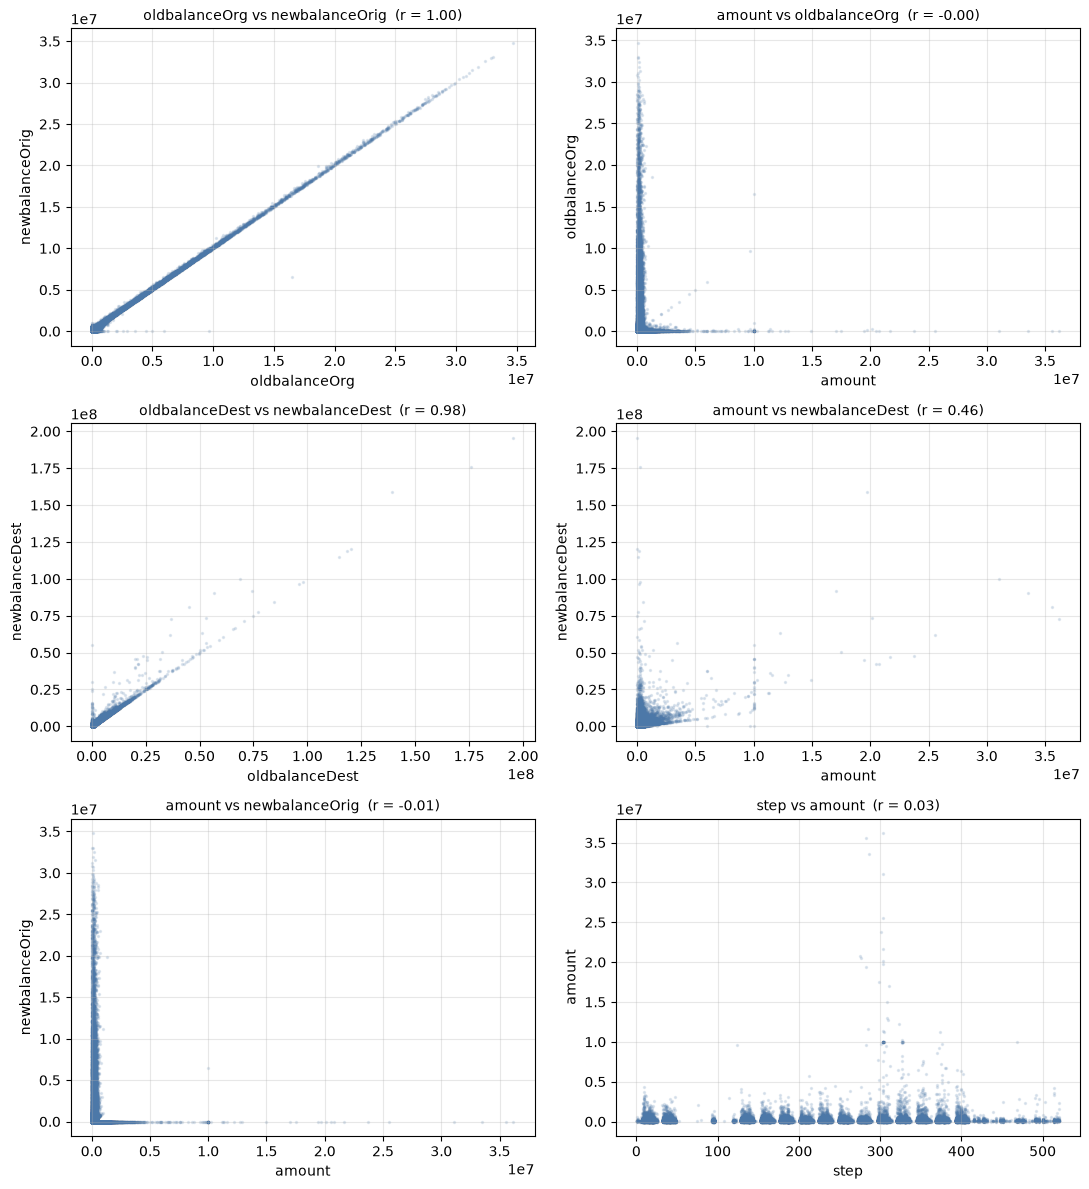

In [9]:
def scatter(ax, a, b, xlabel, ylabel, title):
    ax.scatter(a, b, s=2, alpha=0.15, color="#4C78A8", rasterized=True)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)


def add_fit(ax, a, b):
    slope, intercept = np.polyfit(a, b, 1)
    xs = np.linspace(np.min(a), np.max(a), 100)
    ax.plot(xs, slope * xs + intercept, color="#E45756", lw=1.5)


fig, axes = plt.subplots(3, 2, figsize=(11, 12))
for ax, (x, y) in zip(axes.ravel(), PAIRS):
    scatter(ax, P[x], P[y], x, y, f"{x} vs {y}  (r = {r_coef[(x, y)]:.2f})")
fig.tight_layout()
fig.savefig(FIG_DIR / "bi_02_nuages_bruts.png", dpi=130)
plt.show()

**À interpréter :** pour chaque nuage, dire si les points suivent une droite montante (linéaire positive), une droite descendante (linéaire négative), une courbe (non linéaire) ou ne forment aucune structure (sans relation apparente), puis comparer avec le classement automatique du tableau.

### 4.3 Linéarisation

Quand une relation est courbe ou écrasée par quelques valeurs énormes, on applique **la même transformation aux deux variables** :
- **log(1 + x)** : écrase les grandes valeurs ; le `+1` gère les zéros très fréquents ;
- **racine carrée** : correction plus douce ;
- **Yeo-Johnson** : transformation de puissance choisie automatiquement.

On compare Pearson **avant et après**. Une transformation n'est retenue que si elle améliore |r| d'au moins 0,02 ; sinon on garde les données brutes.

In [10]:
def identity(a, b):
    return a, b


def log_tf(a, b):
    return np.log1p(a), np.log1p(b)


def sqrt_tf(a, b):
    return np.sqrt(a), np.sqrt(b)


def yeo_johnson(a, b):
    out = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(np.column_stack([a, b]))
    return out[:, 0], out[:, 1]


TRANSFORMS = {
    "Brute": identity,
    "log(1+x)": log_tf,
    "Racine carrée": sqrt_tf,
    "Yeo-Johnson": yeo_johnson,
}


def pearson(a, b) -> float:
    c = np.corrcoef(a, b)[0, 1]
    return 0.0 if np.isnan(c) else float(c)


lin_rows = []
best_tf = {}
for x, y in PAIRS:
    a = P[x].to_numpy(dtype=float)
    b = P[y].to_numpy(dtype=float)
    scores = {name: pearson(*f(a, b)) for name, f in TRANSFORMS.items()}
    best = max(scores, key=lambda k: abs(scores[k]))
    if abs(scores[best]) - abs(scores["Brute"]) < 0.02:
        best = "Brute"
    best_tf[(x, y)] = best
    lin_rows.append(
        {
            "Paire": f"{x} vs {y}",
            **{f"r ({k})": v for k, v in scores.items()},
            "Transformation retenue": best,
            "Gain |r|": abs(scores[best]) - abs(scores["Brute"]),
        }
    )

display(pd.DataFrame(lin_rows).round(3))

,Paire,r (Brute),r (log(1+x)),r (Racine carrée),r (Yeo-Johnson),Transformation retenue,Gain |r|
0,oldbalanceOrg vs newbalanceOrig,1.00,0.76,0.99,0.76,Brute,0.00
1,amount vs oldbalanceOrg,-0.01,0.04,0.05,0.04,Racine carrée,0.04
2,oldbalanceDest vs newbalanceDest,0.98,0.88,0.97,0.89,Brute,0.00
3,amount vs newbalanceDest,0.46,0.69,0.56,0.69,Yeo-Johnson,0.23
4,amount vs newbalanceOrig,-0.01,-0.11,0.04,-0.16,Yeo-Johnson,0.15
5,step vs amount,0.03,0.01,0.02,0.01,Brute,0.00


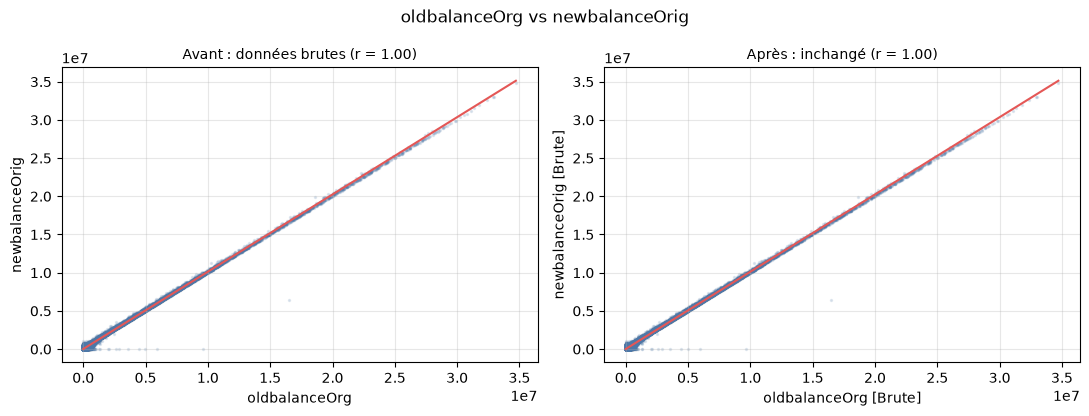

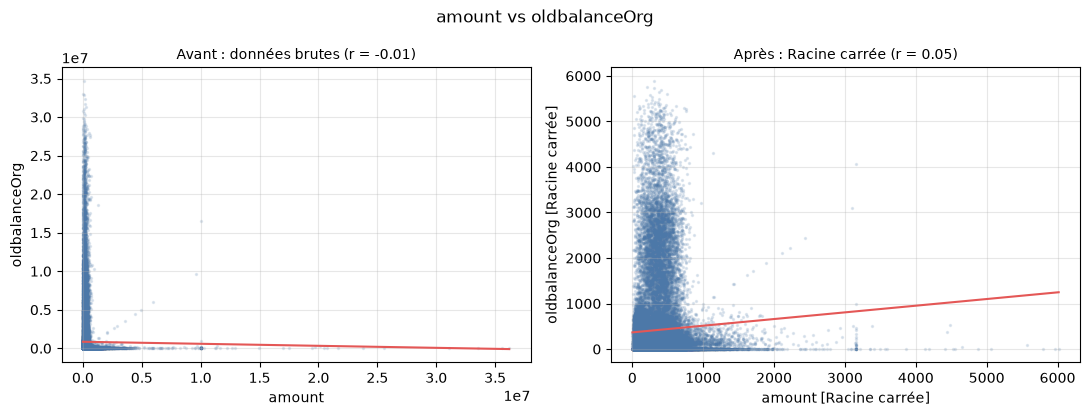

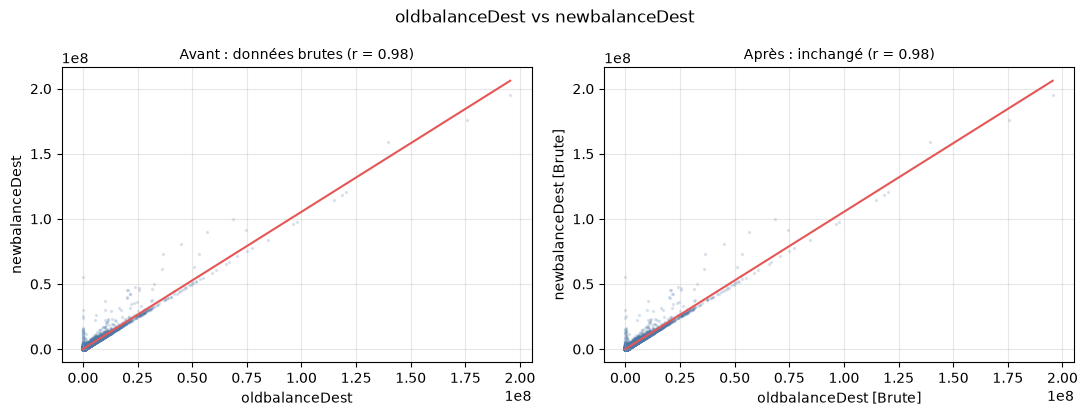

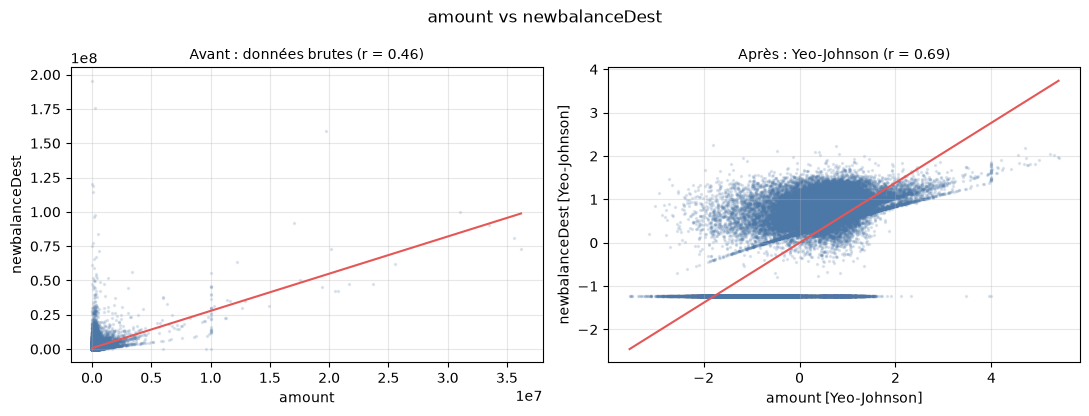

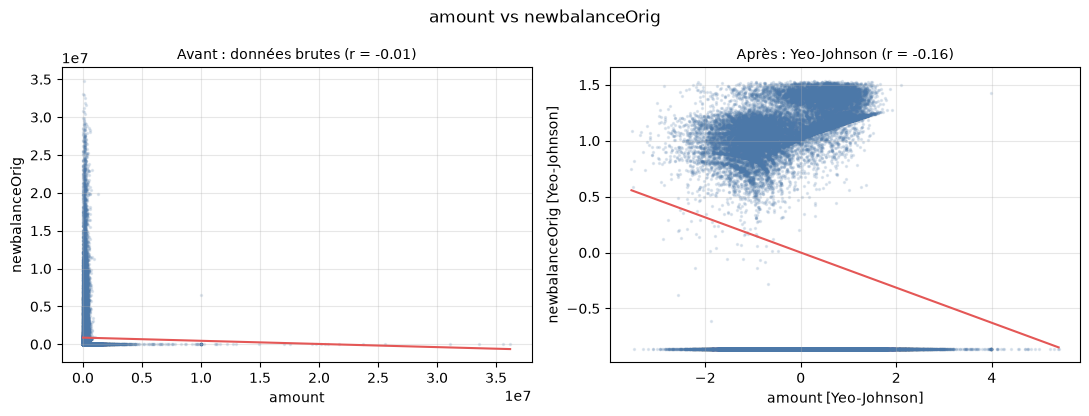

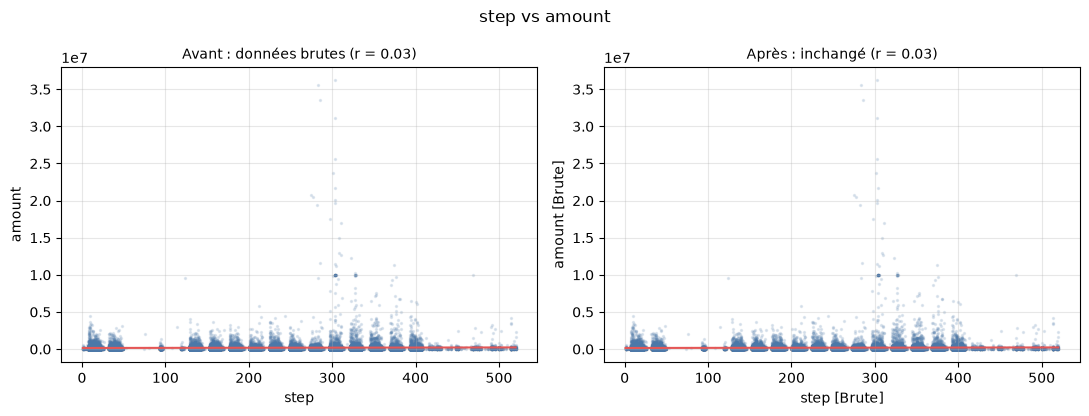

In [11]:
for i, (x, y) in enumerate(PAIRS, start=1):
    a = P[x].to_numpy(dtype=float)
    b = P[y].to_numpy(dtype=float)
    name = best_tf[(x, y)]
    ta, tb = TRANSFORMS[name](a, b)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    scatter(axes[0], a, b, x, y, f"Avant : données brutes (r = {pearson(a, b):.2f})")
    add_fit(axes[0], a, b)
    label = "inchangé" if name == "Brute" else name
    scatter(axes[1], ta, tb, f"{x} [{name}]", f"{y} [{name}]", f"Après : {label} (r = {pearson(ta, tb):.2f})")
    add_fit(axes[1], ta, tb)
    fig.suptitle(f"{x} vs {y}", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"bi_03_pair{i}_avant_apres.png", dpi=130)
    plt.show()

**À interpréter :** pour chaque paire, la transformation a-t-elle rapproché le nuage d'une droite ? De combien Pearson a-t-il changé, et pourquoi (grandes valeurs écrasées, zéros, etc.) ?

### 4.4 Tableau récapitulatif

In [12]:
summary = nature[["Paire", "Pearson r", "Spearman rho", "Nature", "Force (r)"]].copy()
summary.columns = ["Paire", "Pearson brut (r)", "Spearman (rho)", "Nature", "Force (brut)"]
summary["Transformation retenue"] = [best_tf[p] for p in PAIRS]

after = []
for x, y in PAIRS:
    a = P[x].to_numpy(dtype=float)
    b = P[y].to_numpy(dtype=float)
    after.append(pearson(*TRANSFORMS[best_tf[(x, y)]](a, b)))
summary["Pearson après (r)"] = after
summary["R² après"] = summary["Pearson après (r)"] ** 2
summary["Force (après)"] = summary["Pearson après (r)"].map(strength)

display(summary.round(3))
out = REPORTS_DIR / "relations_summary.csv"
summary.round(4).to_csv(out, index=False, encoding="utf-8-sig")
print(f"Tableau enregistré : {out}")

,Paire,Pearson brut (r),Spearman (rho),Nature,Force (brut),Transformation retenue,Pearson après (r),R² après,Force (après)
0,oldbalanceOrg vs newbalanceOrig,1.00,0.80,Linéaire positive,très forte,Brute,1.00,1.00,très forte
1,amount vs oldbalanceOrg,-0.01,0.04,Sans relation apparente,négligeable,Racine carrée,0.05,0.00,négligeable
2,oldbalanceDest vs newbalanceDest,0.98,0.94,Linéaire positive,très forte,Brute,0.98,0.95,très forte
3,amount vs newbalanceDest,0.46,0.67,Non linéaire (ou faible),modérée,Yeo-Johnson,0.69,0.48,forte
4,amount vs newbalanceOrig,-0.01,-0.07,Sans relation apparente,négligeable,Yeo-Johnson,-0.16,0.03,faible
5,step vs amount,0.03,0.00,Sans relation apparente,négligeable,Brute,0.03,0.00,négligeable


Tableau enregistré : C:\Projects\fraudlens\reports\relations_summary.csv


**Remarque méthodologique :** avec autant de points, un test de significativité de Pearson donnerait presque toujours p < 0,001. L'intérêt est donc dans la **valeur de r** et dans la lecture des graphiques, pas dans la p-value.

## 5. Analyse bivariée qualitative x quantitative (optionnelle)

On étudie la relation entre `type` (qualitative) et `amount` (quantitative). La force du lien se mesure avec le **rapport de corrélation η²** : il vaut 0 si le montant ne dépend pas du type, et 1 si le type explique entièrement le montant.

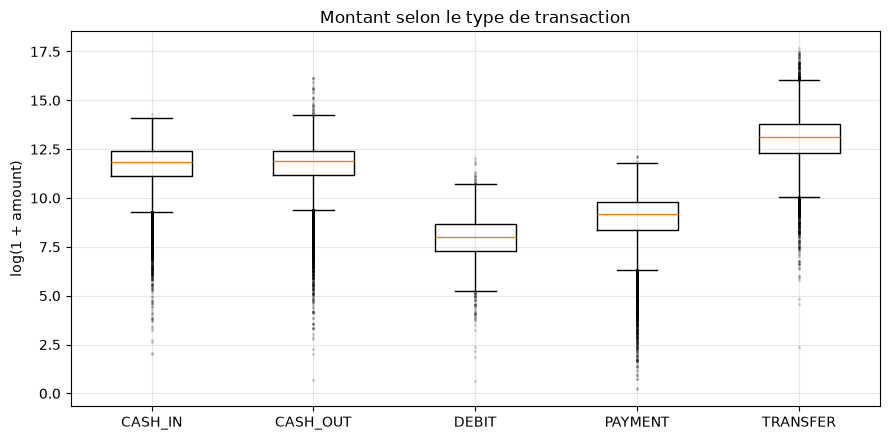

,count,mean,median,std
type,,,,
CASH_IN,44112,"168,298.00","142,427.38","126,620.10"
CASH_OUT,70717,"176,665.71","147,489.84","169,092.26"
DEBIT,1318,"5,510.42","3,062.62","11,079.09"
PAYMENT,67374,"13,065.00","9,510.13","12,569.63"
TRANSFER,16479,"918,104.20","496,825.98","1,885,094.21"


Rapport de corrélation η² (type -> log(1 + amount)) : 0.609


In [13]:
types = sorted(V["type"].astype(str).unique())
y_log = np.log1p(V["amount"].astype(float))
groups = [y_log[V["type"].astype(str) == t] for t in types]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(groups, flierprops={"markersize": 1, "alpha": 0.2})
ax.set_xticklabels(types)
ax.set_ylabel("log(1 + amount)")
ax.set_title("Montant selon le type de transaction")
fig.tight_layout()
fig.savefig(FIG_DIR / "bi_04_montant_par_type.png", dpi=130)
plt.show()

by_type = V.assign(type=V["type"].astype(str)).groupby("type")["amount"].agg(["count", "mean", "median", "std"])
display(by_type)

ss_total = ((y_log - y_log.mean()) ** 2).sum()
ss_between = sum(len(g) * (g.mean() - y_log.mean()) ** 2 for g in groups)
eta2 = ss_between / ss_total
print(f"Rapport de corrélation η² (type -> log(1 + amount)) : {eta2:.3f}")

**À interpréter :** les montants diffèrent-ils nettement selon le type ? Que dit la valeur de η² sur la part de la variation du montant expliquée par le type ?

## 6. Conclusions (à compléter)

- Distributions : forme, asymétrie, zéros, valeurs aberrantes : ...
- Relations **linéaires positives** identifiées : ...
- Relations **linéaires négatives** identifiées : ...
- Relations **non linéaires** et effet de la linéarisation : ...
- Paires **sans relation apparente** : ...
- Lien entre le type de transaction et le montant : ...
- Limites : variables très asymétriques, nombreux zéros, mélange de types de transactions, Pearson sensible aux valeurs extrêmes, corrélation n'implique pas causalité.